## Assignment 1: Data Profiling
### Group Member:
1. AHMAD IRFAN FAIZI BIN MOHD YUSRI (A211206)
2. MUHAMMAD ZAHIN HANAFI BIN ROSGAIDDIN (A211415)
3. MUHAMMAD NAUFAK RIZQI AULIYA (A222945)
4. ZUL RIZA BIN IDRIS (A212679)


### SCENARIO
PropertyWise, a consulting company which help customer identify potential residential property investment opportunities in Hulu Langat, Selangor by using property transaction data obtained from the National Property Information Centre (NAPIC), Malaysia. Before using the dataset, the consultancy needs to evaluate its quality and identify issues that could affect the reliability of subsequent analysis.

### Business Question
Is the dataset that obtained from NAPIC is consistent and accurate enough to be used in property transaction analysis?

### Data Source
Source: National Property Information Centre, NAPIC
URL: https://napic.jpph.gov.my/ms/data-transaksi?category=36&id=241





### Data Profiling and Issue Handling
Initial data profiling was conducted to understand the dataset's structure and assess the completeness of its attributes. The analysis examines data types, non-null records and unique values to identify potential data quality issues that require further investigation.

In [1]:
import os
import pandas as pd

# Load the NAPIC property transaction dataset
df = pd.read_csv(
    "../data/Dataset_PropWise1.csv",
    encoding="utf-16",
    sep="\t"
)

# Initial inspection of the NAPIC dataset

print("Dataset Overview")
print("-----------------")
print("Total records:", df.shape[0])
print("Total columns:", df.shape[1])

# Display the first five records

display(df.head())

# Display all column names

print("Dataset Columns:")
for column in df.columns:
    print("-", repr(column))



Dataset Overview
-----------------
Total records: 1845
Total columns: 14


,Property Type,District,Mukim,Scheme Name/Area,Road Name,"Month, Year of Transaction Date",Tenure,Land/Parcel Area,Unit,Main Floor Area,Unit,Unit Level,Transaction Price,Unnamed: 13
0,Condominium/Apartment,Hulu Langat,Ampang,TAMAN BUKIT SEGAR EMAS/CHERAS HARTAMAS,,April 2026,Leasehold,70.0,sq.m,-,-,1,"RM267,000.00",NaN
1,Condominium/Apartment,Hulu Langat,Ampang,TAMAN DATOK AHMAD RAZALI,,April 2026,Leasehold,85.0,sq.m,-,-,G,"RM400,000.00",NaN
2,Condominium/Apartment,Hulu Langat,Ampang,TAMAN DATOK AHMAD RAZALI,,April 2026,Leasehold,107.0,sq.m,-,-,2,"RM450,000.00",NaN
3,Condominium/Apartment,Hulu Langat,Ampang,TAMAN DATOK AHMAD RAZALI,,May 2026,Leasehold,100.0,sq.m,-,-,1,"RM390,000.00",NaN
4,Condominium/Apartment,Hulu Langat,Ampang,TAMAN PANDAN INDAH,,August 2025,Leasehold,82.0,sq.m,-,-,4&5,"RM330,000.00",NaN


Dataset Columns:
- 'Property Type'
- 'District'
- 'Mukim'
- 'Scheme Name/Area'
- 'Road Name'
- 'Month, Year of Transaction Date'
- 'Tenure'
- 'Land/Parcel Area'
- 'Unit'
- 'Main Floor Area'
- 'Unit        '
- 'Unit Level'
- 'Transaction Price  '
- 'Unnamed: 13'


In [2]:
profile = pd.DataFrame({
    "Column": df.columns,
    "Data Type": df.dtypes.astype(str).values,
    "Non-Null Count": df.notna().sum().values,
    "Unique Values": df.nunique().values
})

display(profile)

,Column,Data Type,Non-Null Count,Unique Values
0,Property Type,str,1845,1
1,District,str,1845,1
2,Mukim,str,1845,17
3,Scheme Name/Area,str,1845,218
4,Road Name,str,1845,1
5,"Month, Year of Transaction Date",str,1845,30
6,Tenure,str,1845,2
7,Land/Parcel Area,float64,1845,199
8,Unit,str,1845,1
9,Main Floor Area,str,1845,1


In [3]:
import numpy as np

df_clean = df.copy()

# Convert empty strings and whitespace-only values to NaN
df_clean = df_clean.replace(
    r"^\s*$",
    np.nan,
    regex=True
)

# Convert hyphen placeholders to NaN
df_clean = df_clean.replace("-", np.nan)

print("Missing-value placeholders converted to NaN.")

Missing-value placeholders converted to NaN.


In [4]:
missing_table = pd.DataFrame({
    "Column": df_clean.columns,
    "Missing Count": df_clean.isnull().sum().values,
    "Missing Percentage": (
        df_clean.isnull().mean().values * 100
    ).round(2)
})

missing_table = missing_table.sort_values(
    "Missing Count",
    ascending=False
)

display(missing_table)

,Column,Missing Count,Missing Percentage
4,Road Name,1845,100.0
9,Main Floor Area,1845,100.0
10,Unit,1845,100.0
13,Unnamed: 13,1845,100.0
1,District,0,0.0
0,Property Type,0,0.0
5,"Month, Year of Transaction Date",0,0.0
3,Scheme Name/Area,0,0.0
2,Mukim,0,0.0
6,Tenure,0,0.0


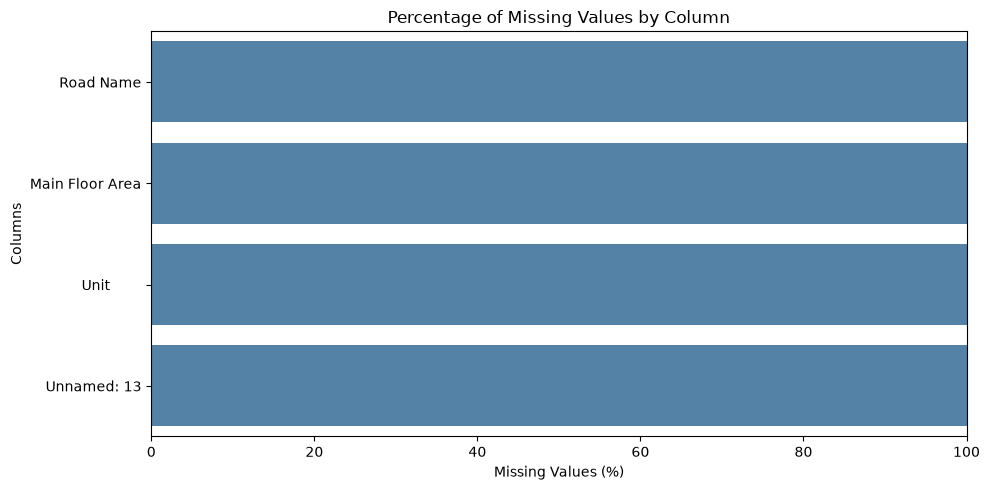

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

missing_plot = missing_table[
    missing_table["Missing Count"] > 0
]

plt.figure(figsize=(10, 5))

sns.barplot(
    data=missing_plot,
    x="Missing Percentage",
    y="Column",
    color="steelblue"
)

plt.title("Percentage of Missing Values by Column")
plt.xlabel("Missing Values (%)")
plt.ylabel("Columns")
plt.xlim(0, 100)
plt.tight_layout()
plt.show()

### Data Profiling Finding
The initial data profiling examined the dataset's structure, data types, unique values and completeness across 1,845 records and 14 columns. The analysis identified potential data quality issues involving missing values and column structure.

The missing-value analysis revealed that **four columns had 100% missing values**, affecting all 1,845 records. These columns were Road Name, Main Floor Area, Unit and Unnamed: 13. The remaining columns showed 0% missing values based on the current profiling results.

The initial profiling also identified an unnamed column with no non-null values and two columns labelled [Unit]. These findings indicate potential structural issues that require further investigation. In addition, several categorical attributes, including Property Type, District and Road Name, had only one unique value in the initial profiling results, which may indicate limited variation or missing information.

Overall, the results highlight potential completeness and structural issues that should be investigated before the dataset is used for further analysis. The next stage will verify the affected columns and examine other data quality issues, including invalid values, inconsistencies and potential outliers, before determining the appropriate data cleaning methods.
